<div class="alert alert-block alert-success">
    <h1 align="center">Machine Learning in Python</h1>
    <h3 align="center">Project1</h3>
</div>

<img src = "https://www.eesc.europa.eu/sites/default/files/styles/large/public/images/shutterstock_1642888921.jpg?itok=P9-6YhGd" width=50%>

## Importing the libraries

In [25]:
import warnings
warnings.filterwarnings("ignore")

In [26]:
import numpy as np
import pandas as pd

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
import joblib

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## Load and Prepare Data

In [29]:
# Read both raw datasets directly from the working directory
vacc_raw = pd.read_csv("country_vaccinations.csv")
manufacturer_raw = pd.read_csv("country_vaccinations_by_manufacturer.csv")

print("Vaccinations shape:", vacc_raw.shape)
print("Manufacturer data shape:", manufacturer_raw.shape)

Vaccinations shape: (31240, 15)
Manufacturer data shape: (9157, 4)


In [30]:
# Preview head observations of both datasets
display(vacc_raw.head())
display(manufacturer_raw.head())

,country,iso_code,date,total_vaccinations,people_vaccinated,people_fully_vaccinated,daily_vaccinations_raw,daily_vaccinations,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,daily_vaccinations_per_million,vaccines,source_name,source_website
0,Afghanistan,AFG,2021-02-22,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/
1,Afghanistan,AFG,2021-02-23,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,35.0,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/
2,Afghanistan,AFG,2021-02-24,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,35.0,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/
3,Afghanistan,AFG,2021-02-25,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,35.0,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/
4,Afghanistan,AFG,2021-02-26,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,35.0,"Johnson&Johnson, Oxford/AstraZeneca, Pfizer/Bi...",World Health Organization,https://covid19.who.int/


,location,date,vaccine,total_vaccinations
0,Austria,2021-01-08,Johnson&Johnson,0
1,Austria,2021-01-08,Moderna,0
2,Austria,2021-01-08,Oxford/AstraZeneca,0
3,Austria,2021-01-08,Pfizer/BioNTech,30974
4,Austria,2021-01-15,Johnson&Johnson,0


In [31]:
# Inspect column attributes and initial datatype assignments
print("Vaccinations columns:", vacc_raw.columns.tolist())
print("Manufacturer columns:", manufacturer_raw.columns.tolist())
print("\nVaccinations dtypes:\n", vacc_raw.dtypes)

Vaccinations columns: ['country', 'iso_code', 'date', 'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated', 'daily_vaccinations_raw', 'daily_vaccinations', 'total_vaccinations_per_hundred', 'people_vaccinated_per_hundred', 'people_fully_vaccinated_per_hundred', 'daily_vaccinations_per_million', 'vaccines', 'source_name', 'source_website']
Manufacturer columns: ['location', 'date', 'vaccine', 'total_vaccinations']

Vaccinations dtypes:
 country                                    str
iso_code                                   str
date                                       str
total_vaccinations                     float64
people_vaccinated                      float64
people_fully_vaccinated                float64
daily_vaccinations_raw                 float64
daily_vaccinations                     float64
total_vaccinations_per_hundred         float64
people_vaccinated_per_hundred          float64
people_fully_vaccinated_per_hundred    float64
daily_vaccinations_per_mill

In [32]:
# Convert date attributes to standard datetime objects
vacc = vacc_raw.copy()
manufacturer = manufacturer_raw.copy()

vacc["date"] = pd.to_datetime(vacc["date"], errors="coerce")
manufacturer["date"] = pd.to_datetime(manufacturer["date"], errors="coerce")

print("Invalid vaccination dates:", vacc["date"].isna().sum())
print("Invalid manufacturer dates:", manufacturer["date"].isna().sum())

Invalid vaccination dates: 0
Invalid manufacturer dates: 0


In [33]:
# Cast all quantitative vaccination features into explicit numeric types
numeric_columns = [
    "total_vaccinations",
    "people_vaccinated",
    "people_fully_vaccinated",
    "daily_vaccinations_raw",
    "daily_vaccinations",
    "total_vaccinations_per_hundred",
    "people_vaccinated_per_hundred",
    "people_fully_vaccinated_per_hundred",
    "daily_vaccinations_per_million",
]

for column in numeric_columns:
    vacc[column] = pd.to_numeric(vacc[column], errors="coerce")

manufacturer["total_vaccinations"] = pd.to_numeric(
    manufacturer["total_vaccinations"], errors="coerce"
)

In [34]:
# Display descriptive high-level dataset metrics
print("Vaccination data dimensions:", vacc.shape)
print("Unique countries:", vacc["country"].nunique())
print("Date range:", vacc["date"].min(), "to", vacc["date"].max())
print("Manufacturer locations:", manufacturer["location"].nunique())
print("Manufacturer vaccines:", manufacturer["vaccine"].nunique())

Vaccination data dimensions: (31240, 15)
Unique countries: 218
Date range: 2020-12-02 00:00:00 to 2021-07-15 00:00:00
Manufacturer locations: 33
Manufacturer vaccines: 8


In [35]:
# Drop empty identifier rows and enforce ascending chronological sorting
vacc = (
    vacc.dropna(subset=["country", "date"])
    .sort_values(["country", "date"])
    .reset_index(drop=True)
)

manufacturer = (
    manufacturer.dropna(subset=["location", "date", "vaccine"])
    .sort_values(["location", "date", "vaccine"])
    .reset_index(drop=True)
)

In [36]:
# Verify cleaned shapes and valid time spans
print("Vaccination data rows after basic date checks:", len(vacc))
print("Manufacturer data rows after basic date checks:", len(manufacturer))
print("Vaccination date range:", vacc["date"].min(), "to", vacc["date"].max())

Vaccination data rows after basic date checks: 31240
Manufacturer data rows after basic date checks: 9157
Vaccination date range: 2020-12-02 00:00:00 to 2021-07-15 00:00:00


## EDA

In [37]:
# Display structural overview and memory footprints
vacc.info()

<class 'pandas.DataFrame'>
RangeIndex: 31240 entries, 0 to 31239
Data columns (total 15 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   country                              31240 non-null  str           
 1   iso_code                             31240 non-null  str           
 2   date                                 31240 non-null  datetime64[us]
 3   total_vaccinations                   17451 non-null  float64       
 4   people_vaccinated                    16554 non-null  float64       
 5   people_fully_vaccinated              13795 non-null  float64       
 6   daily_vaccinations_raw               14421 non-null  float64       
 7   daily_vaccinations                   30948 non-null  float64       
 8   total_vaccinations_per_hundred       17451 non-null  float64       
 9   people_vaccinated_per_hundred        16554 non-null  float64       
 10  people_fully_vaccinat

In [38]:
# Generate comprehensive summary statistics for all attributes
display(vacc.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
country,31240,218,Norway,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iso_code,31240,218,NOR,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,31240,NaN,NaN,NaN,2021-04-22 23:08:14.135723,2020-12-02 00:00:00,2021-03-16 00:00:00,2021-04-28 00:00:00,2021-06-05 00:00:00,2021-07-15 00:00:00,NaN
total_vaccinations,17451.0,NaN,NaN,NaN,12004435.249842,0.0,126201.5,889078.0,4213660.0,1426347000.0,66223487.901778
people_vaccinated,16554.0,NaN,NaN,NaN,5704550.528452,0.0,99991.0,645039.5,2809300.5,622000000.0,21016117.637804
people_fully_vaccinated,13795.0,NaN,NaN,NaN,3293973.392896,1.0,48324.5,363210.0,1635366.0,223299000.0,12344246.970467
daily_vaccinations_raw,14421.0,NaN,NaN,NaN,227366.073989,0.0,4324.0,21336.0,94417.0,24741000.0,1258555.690975
daily_vaccinations,30948.0,NaN,NaN,NaN,114971.789486,0.0,852.0,6471.0,35454.25,22424286.0,846054.828829
total_vaccinations_per_hundred,17451.0,NaN,NaN,NaN,29.283554,0.0,2.97,14.51,44.46,232.35,35.042304
people_vaccinated_per_hundred,16554.0,NaN,NaN,NaN,19.181574,0.0,2.58,10.73,30.89,116.66,20.734193


In [39]:
# Quantify missing value rates and counts across features
missing_counts = vacc.isna().sum().sort_values(ascending=False)
missing_rates = (vacc.isna().mean() * 100).sort_values(ascending=False)

display(pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": missing_rates
}))

,missing_count,missing_percent
people_fully_vaccinated,17445,55.841869
people_fully_vaccinated_per_hundred,17445,55.841869
daily_vaccinations_raw,16819,53.838028
people_vaccinated_per_hundred,14686,47.010243
people_vaccinated,14686,47.010243
total_vaccinations,13789,44.138924
total_vaccinations_per_hundred,13789,44.138924
daily_vaccinations_per_million,292,0.934699
daily_vaccinations,292,0.934699
date,0,0.000000


In [40]:
# Check for key duplication across country-date and location-date-vaccine tuples
vacc_duplicate_count = vacc.duplicated(subset=["country", "date"]).sum()
manufacturer_duplicate_count = manufacturer.duplicated(subset=["location", "date", "vaccine"]).sum()

print("Duplicate country-date rows:", vacc_duplicate_count)
print("Duplicate location-date-vaccine rows:", manufacturer_duplicate_count)

Duplicate country-date rows: 0
Duplicate location-date-vaccine rows: 0


In [41]:
# Evaluate monotonicity in cumulative vaccinations per country
total_rows = vacc.dropna(subset=["total_vaccinations"]).copy()
total_rows["total_change"] = total_rows.groupby("country")["total_vaccinations"].diff()

decrease_rows = total_rows[total_rows["total_change"] < 0]
print("Rows with a decrease in cumulative totals:", len(decrease_rows))
display(decrease_rows[["country", "date", "total_vaccinations", "total_change"]].head())

Rows with a decrease in cumulative totals: 0


,country,date,total_vaccinations,total_change


In [42]:
# Examine time coverage, recorded days, and final recorded totals per country
country_coverage = (
    vacc.groupby("country")
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        rows=("date", "size"),
        latest_total=("total_vaccinations", "last"),
    )
    .sort_values("rows", ascending=False)
)

display(country_coverage.head(15))

,first_date,last_date,rows,latest_total
country,,,,
Norway,2020-12-02,2021-07-15,226,4.856669e+06
Latvia,2020-12-04,2021-07-15,224,1.264433e+06
England,2020-12-08,2021-07-15,220,6.847415e+07
Scotland,2020-12-08,2021-07-15,220,6.903704e+06
Northern Ireland,2020-12-13,2021-07-15,215,2.153395e+06
Wales,2020-12-13,2021-07-15,215,4.171221e+06
United Kingdom,2020-12-13,2021-07-15,215,8.170247e+07
Canada,2020-12-14,2021-07-15,214,4.429366e+07
China,2020-12-15,2021-07-15,213,1.426347e+09


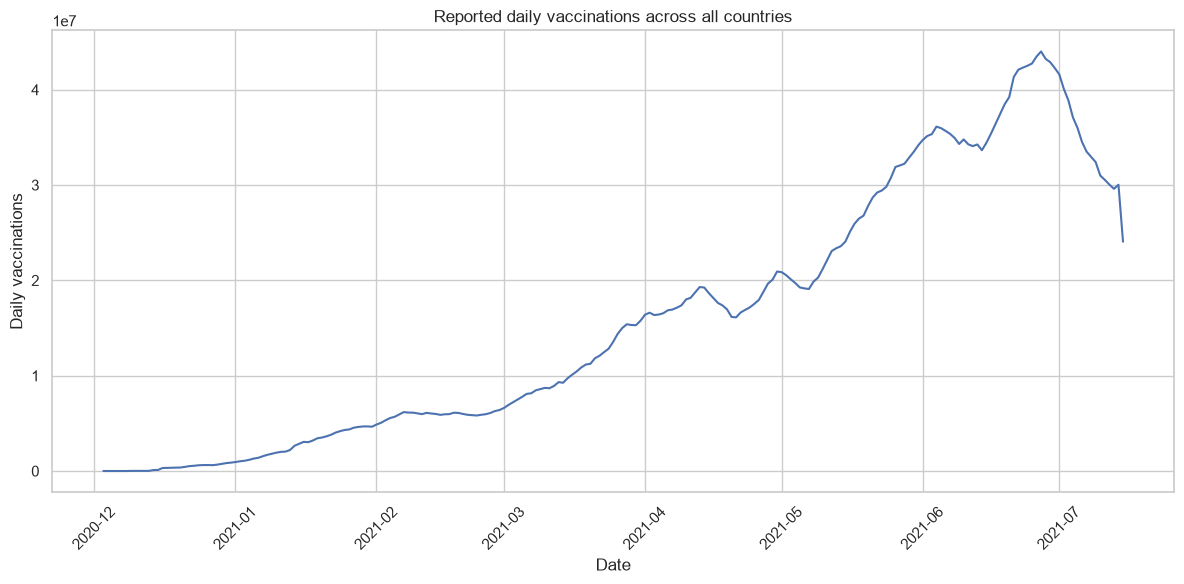

In [43]:
# Plot aggregate global daily vaccination trends over time
daily_global = (
    vacc.groupby("date", as_index=False)["daily_vaccinations"]
    .sum(min_count=1)
    .sort_values("date")
)

plt.plot(daily_global["date"], daily_global["daily_vaccinations"])
plt.title("Reported daily vaccinations across all countries")
plt.xlabel("Date")
plt.ylabel("Daily vaccinations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
# Display top 10 nations by cumulative administered doses
top_countries = (
    vacc.dropna(subset=["total_vaccinations"])
    .sort_values("date")
    .groupby("country")["total_vaccinations"]
    .last()
    .nlargest(10)
)

display(top_countries)

country
China             1.426347e+09
India             3.913405e+08
United States     3.360550e+08
Brazil            1.208730e+08
Germany           8.498985e+07
United Kingdom    8.170247e+07
England           6.847415e+07
Japan             6.671453e+07
France            6.317486e+07
Turkey            6.237883e+07
Name: total_vaccinations, dtype: float64

## Data Preprocessing

In [45]:
# Deduplicate observations keeping only the most recently updated record
vacc = (
    vacc.drop_duplicates(subset=["country", "date"], keep="last")
    .sort_values(["country", "date"])
    .reset_index(drop=True)
)

manufacturer = (
    manufacturer.drop_duplicates(
        subset=["location", "date", "vaccine"], keep="last"
    )
    .sort_values(["location", "date", "vaccine"])
    .reset_index(drop=True)
)

In [46]:
# Perform bidirectional linear interpolation on daily vaccinations within each country
vacc["daily_vaccinations"] = vacc.groupby("country")[
    "daily_vaccinations"
].transform(lambda series: series.interpolate(limit_direction="both"))

In [47]:
# Apply percentile-based winsorization to control severe reporting spikes
def winsorize_series(series, lower_quantile=0.01, upper_quantile=0.99):
    lower = series.quantile(lower_quantile)
    upper = series.quantile(upper_quantile)
    return series.clip(lower=lower, upper=upper)

vacc["daily_vaccinations_winsorized"] = vacc.groupby("country")[
    "daily_vaccinations"
].transform(winsorize_series)

print(
    "Winsorized values changed:",
    (vacc["daily_vaccinations"] != vacc["daily_vaccinations_winsorized"]).sum()
)

Winsorized values changed: 596


In [48]:
# Designate representative country with dense historical records
COUNTRY = "United States"

country_data = (
    vacc[vacc["country"] == COUNTRY]
    .sort_values("date")
    .copy()
    .reset_index(drop=True)
)

if country_data.empty:
    raise ValueError(f"{COUNTRY!r} is not present in the vaccination data.")

print(COUNTRY, "rows:", len(country_data))
print("Date range:", country_data["date"].min(), "to", country_data["date"].max())

United States rows: 208
Date range: 2020-12-20 00:00:00 to 2021-07-15 00:00:00


In [49]:
# Resample time-series figures to weekly aggregated steps per nation
weekly_by_country = (
    vacc.set_index("date")
    .groupby("country")
    .resample("W")
    .agg({
        "total_vaccinations": "last",
        "daily_vaccinations": "mean",
    })
    .reset_index()
)

display(weekly_by_country.head())
print("Weekly resampled rows:", len(weekly_by_country))

,country,date,total_vaccinations,daily_vaccinations
0,Afghanistan,2021-02-28,8200.0,1367.000000
1,Afghanistan,2021-03-07,NaN,2221.285714
2,Afghanistan,2021-03-14,NaN,2862.000000
3,Afghanistan,2021-03-21,54000.0,2904.428571
4,Afghanistan,2021-03-28,NaN,2997.142857


Weekly resampled rows: 4664


In [50]:
# Generate calendar attributes and daily changes for time dynamics
vacc["year"] = vacc["date"].dt.year
vacc["month"] = vacc["date"].dt.month
vacc["day_of_week"] = vacc["date"].dt.dayofweek
vacc["total_change"] = vacc.groupby("country")["total_vaccinations"].diff()

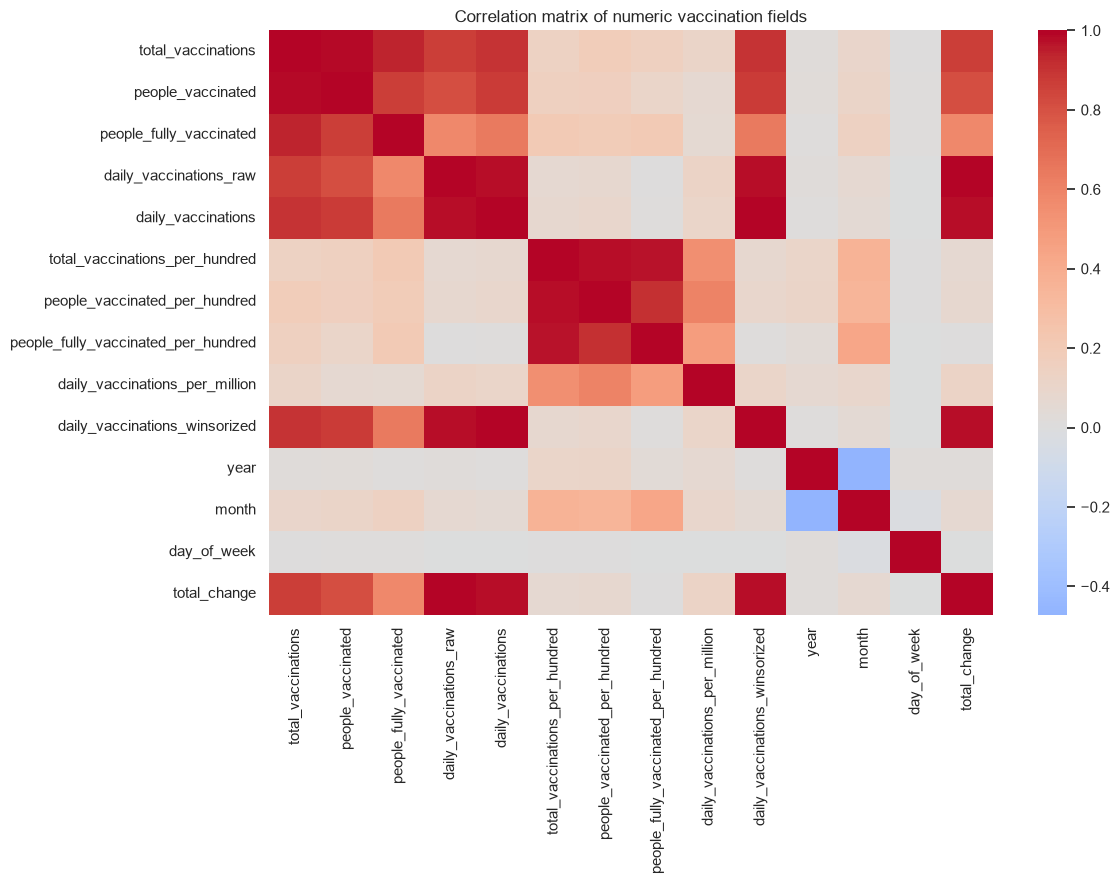

In [51]:
# Plot correlation matrix across numeric features
numeric_data = vacc.select_dtypes(include=np.number)
correlation = numeric_data.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Correlation matrix of numeric vaccination fields")
plt.tight_layout()
plt.show()

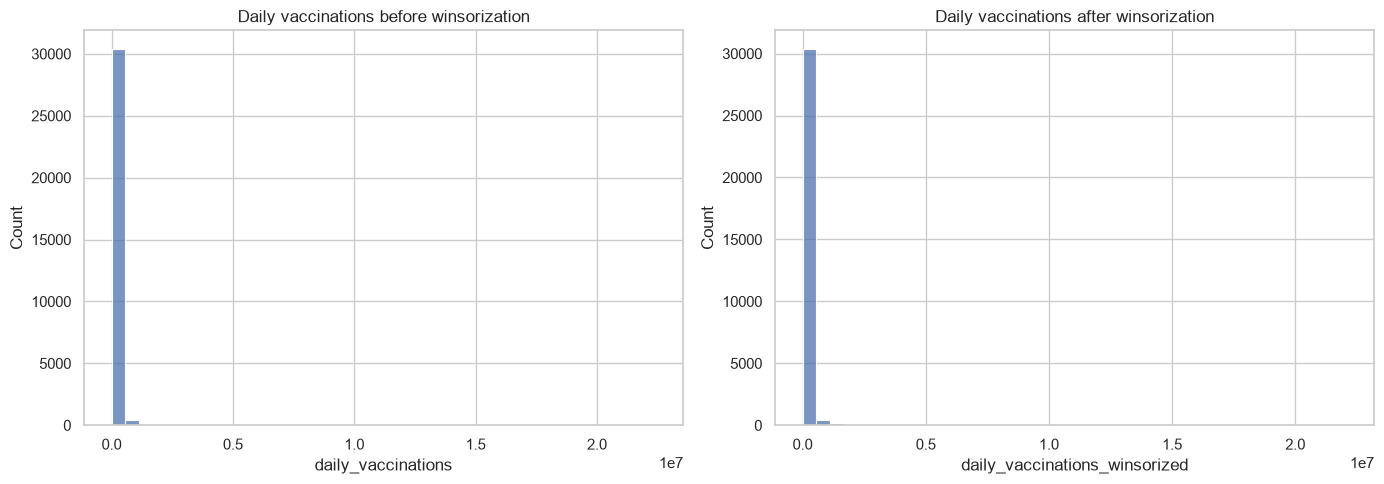

In [52]:
# Compare daily distributions before and after outlier winsorization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(vacc["daily_vaccinations"].dropna(), bins=40, ax=axes[0])
axes[0].set_title("Daily vaccinations before winsorization")

sns.histplot(vacc["daily_vaccinations_winsorized"].dropna(), bins=40, ax=axes[1])
axes[1].set_title("Daily vaccinations after winsorization")

plt.tight_layout()
plt.show()

## Strorytelling - Visualization

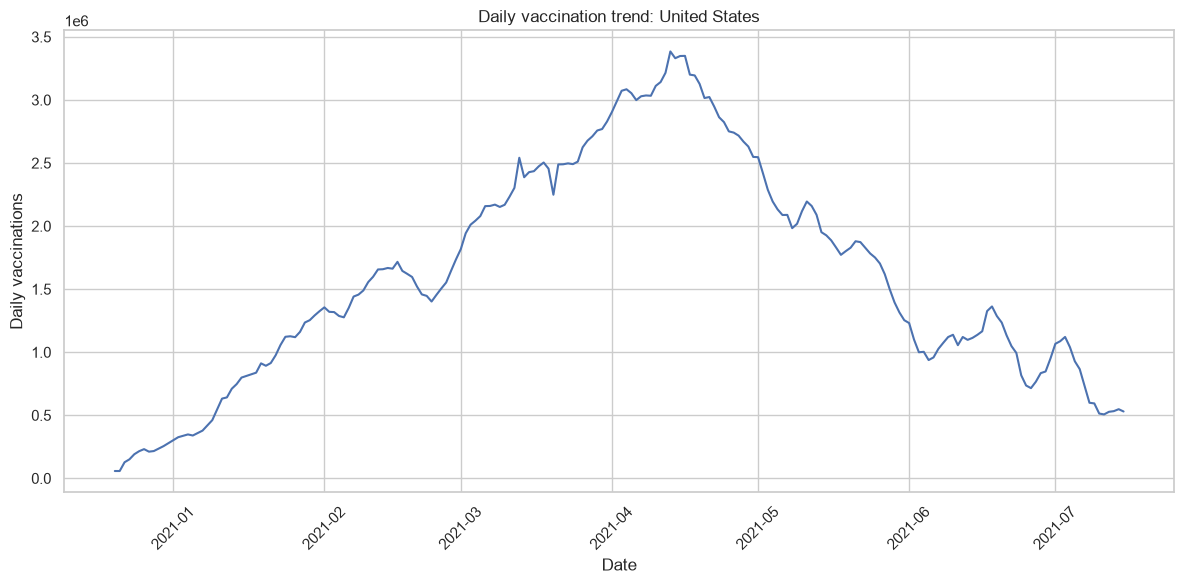

In [53]:
# Plot timeline of daily administration figures for the primary selected nation
selected_plot = country_data.dropna(subset=["daily_vaccinations"])

plt.plot(selected_plot["date"], selected_plot["daily_vaccinations"])
plt.title(f"Daily vaccination trend: {COUNTRY}")
plt.xlabel("Date")
plt.ylabel("Daily vaccinations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

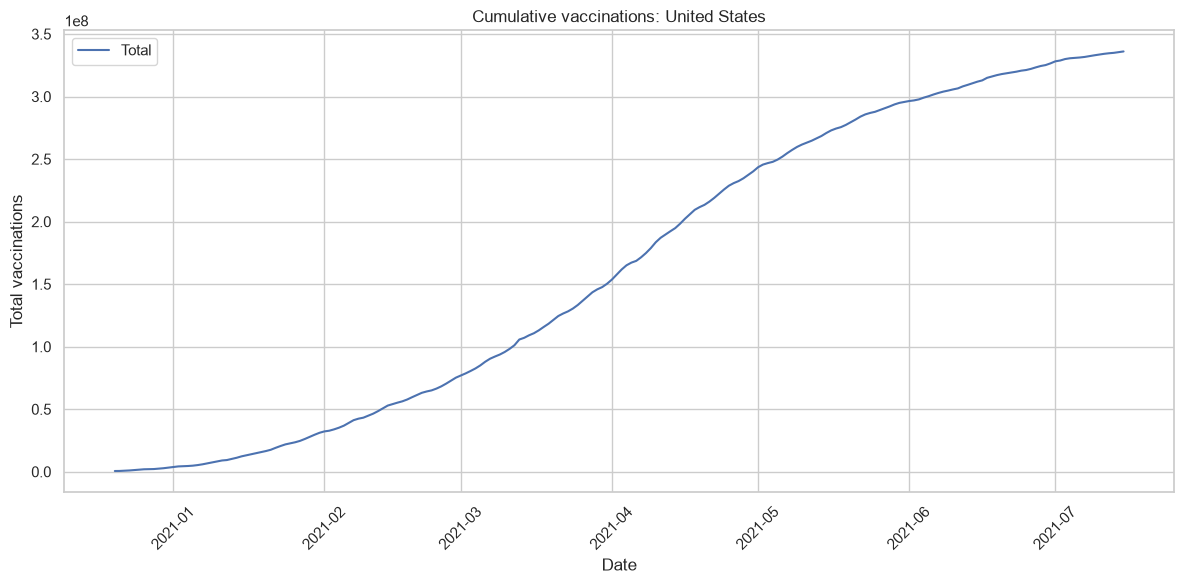

In [54]:
# Plot cumulative doses progression over campaign duration
selected_plot = country_data.dropna(subset=["total_vaccinations"])

plt.plot(selected_plot["date"], selected_plot["total_vaccinations"], label="Total")
plt.title(f"Cumulative vaccinations: {COUNTRY}")
plt.xlabel("Date")
plt.ylabel("Total vaccinations")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [55]:
# Resample monthly averages and closing totals for the target country
monthly_country = (
    country_data.set_index("date")
    .resample("MS")
    .agg({
        "daily_vaccinations": "mean",
        "total_vaccinations": "last",
    })
    .reset_index()
)

display(monthly_country.head())

,date,daily_vaccinations,total_vaccinations
0,2020-12-01,1.857251e+05,2794588.0
1,2021-01-01,7.808311e+05,31123299.0
2,2021-02-01,1.513967e+06,75236003.0
3,2021-03-01,2.372705e+06,150273292.0
4,2021-04-01,3.011027e+06,240159677.0


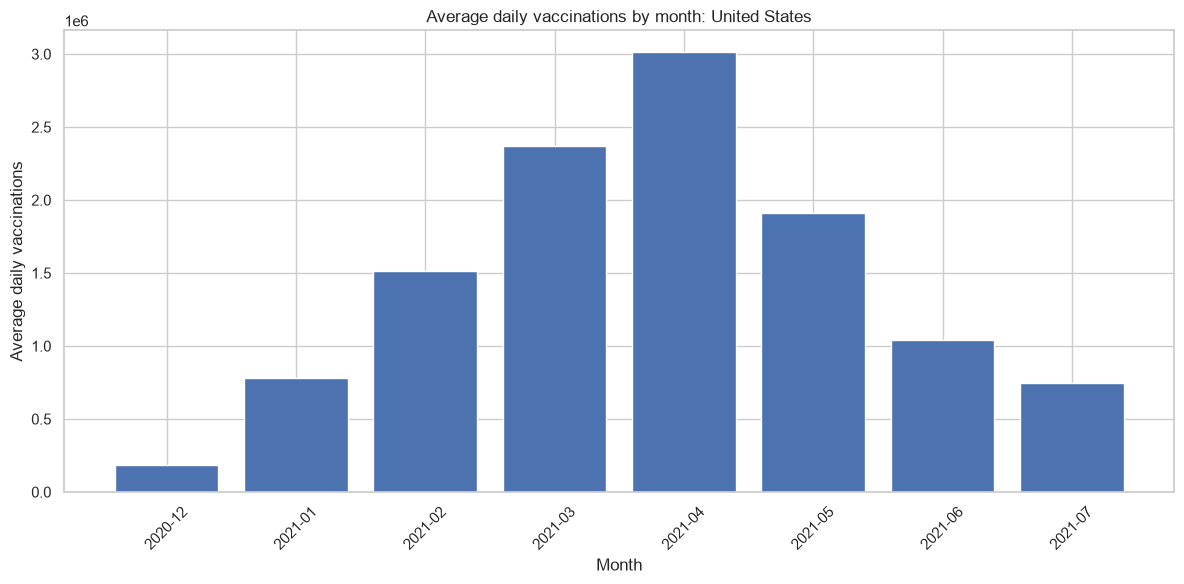

In [56]:
# Bar chart of monthly mean vaccination rate
plt.bar(
    monthly_country["date"].dt.strftime("%Y-%m"),
    monthly_country["daily_vaccinations"],
)
plt.title(f"Average daily vaccinations by month: {COUNTRY}")
plt.xlabel("Month")
plt.ylabel("Average daily vaccinations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

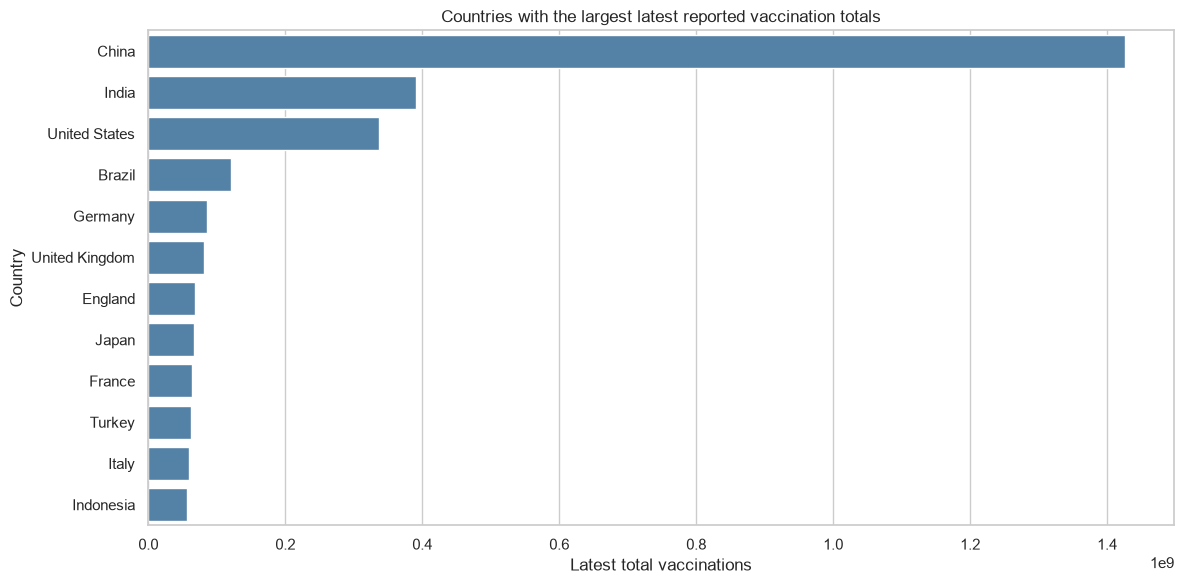

In [57]:
# Bar plot highlighting the top 12 countries with the highest total vaccinations
country_total_latest = (
    vacc.dropna(subset=["total_vaccinations"])
    .sort_values("date")
    .groupby("country")
    .tail(1)
    .nlargest(12, "total_vaccinations")
)

sns.barplot(
    data=country_total_latest,
    x="total_vaccinations",
    y="country",
    color="steelblue",
)
plt.title("Countries with the largest latest reported vaccination totals")
plt.xlabel("Latest total vaccinations")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [58]:
# Filter manufacturer tracking data for the designated country
selected_manufacturer = manufacturer[
    manufacturer["location"] == COUNTRY
].copy()

print("Manufacturer rows for selected country:", len(selected_manufacturer))
display(selected_manufacturer.head())

Manufacturer rows for selected country: 484


,location,date,vaccine,total_vaccinations
8256,United States,2021-01-12,Moderna,3835859
8257,United States,2021-01-12,Pfizer/BioNTech,5488697
8258,United States,2021-01-13,Moderna,4249795
8259,United States,2021-01-13,Pfizer/BioNTech,6025872
8260,United States,2021-01-15,Moderna,5122662


In [59]:
# Quantify final cumulative doses by manufacturer
manufacturer_latest = (
    selected_manufacturer.sort_values("date")
    .groupby("vaccine")["total_vaccinations"]
    .last()
    .sort_values(ascending=False)
)

display(manufacturer_latest.to_frame("latest_total_vaccinations"))

,latest_total_vaccinations
vaccine,
Pfizer/BioNTech,186509204
Moderna,136332425
Johnson&Johnson,12936594


In [60]:
# Compute percentage share distribution among authorized manufacturers
manufacturer_total = manufacturer_latest.sum()

if manufacturer_total > 0:
    manufacturer_share = (manufacturer_latest / manufacturer_total).sort_values(
        ascending=False
    )
else:
    manufacturer_share = manufacturer_latest * np.nan

display(manufacturer_share.to_frame("share"))

,share
vaccine,
Pfizer/BioNTech,0.555454
Moderna,0.406019
Johnson&Johnson,0.038527


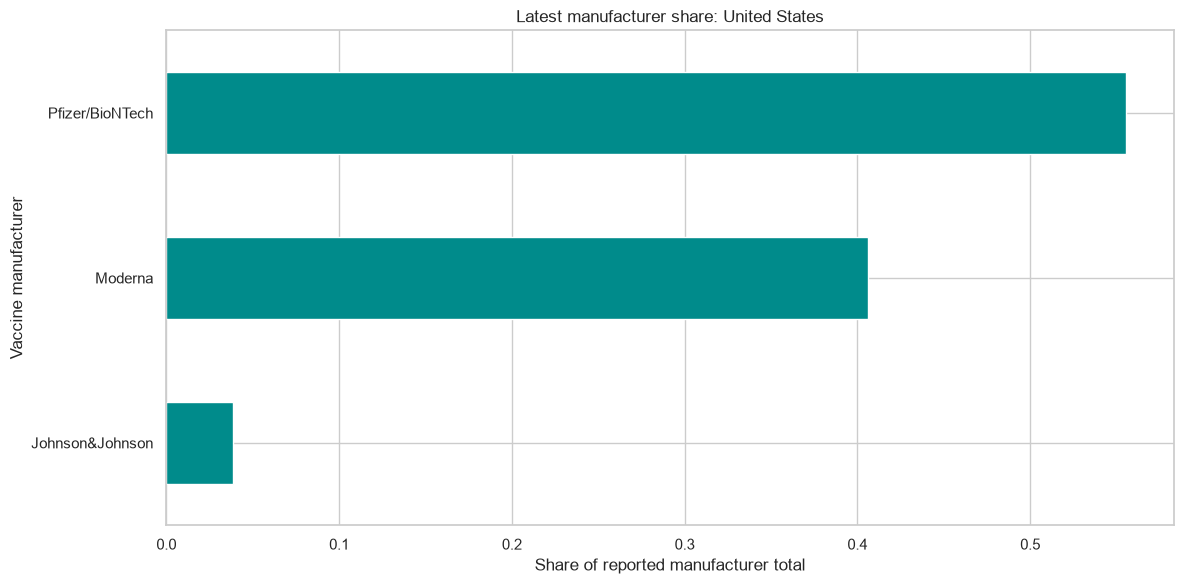

In [61]:
# Visualize manufacturer distribution as horizontal bar plot
if manufacturer_share.notna().any():
    manufacturer_share.sort_values().plot(
        kind="barh",
        color="darkcyan",
    )
    plt.title(f"Latest manufacturer share: {COUNTRY}")
    plt.xlabel("Share of reported manufacturer total")
    plt.ylabel("Vaccine manufacturer")
    plt.tight_layout()
    plt.show()
else:
    print("No positive manufacturer totals are available for the selected country.")

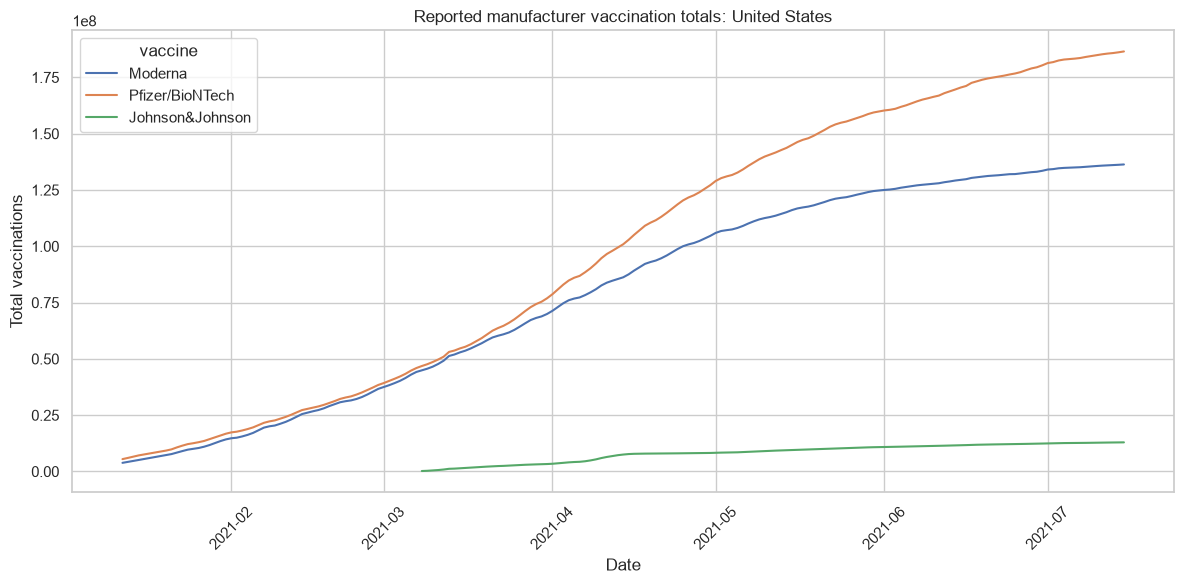

In [62]:
# Plot longitudinal rollout trajectories by manufacturer type
if not selected_manufacturer.empty:
    sns.lineplot(
        data=selected_manufacturer,
        x="date",
        y="total_vaccinations",
        hue="vaccine",
    )
    plt.title(f"Reported manufacturer vaccination totals: {COUNTRY}")
    plt.xlabel("Date")
    plt.ylabel("Total vaccinations")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Prepare Data for Machine learning

In [63]:
# Extract target country time series utilizing winsorized daily inputs
model_data = (
    vacc[vacc["country"] == COUNTRY]
    .sort_values("date")
    .loc[:, ["date", "daily_vaccinations_winsorized"]]
    .rename(columns={"daily_vaccinations_winsorized": "daily_vaccinations"})
    .copy()
    .reset_index(drop=True)
)

print("Modeling rows before feature engineering:", len(model_data))

Modeling rows before feature engineering: 208


In [64]:
# Construct lag features and moving-window statistics
model_data["daily_lag_1"] = model_data["daily_vaccinations"].shift(1)
model_data["daily_lag_7"] = model_data["daily_vaccinations"].shift(7)
model_data["rolling_mean_7"] = model_data["daily_vaccinations"].rolling(
    window=7, min_periods=3
).mean()
model_data["rolling_std_7"] = model_data["daily_vaccinations"].rolling(
    window=7, min_periods=3
).std()

In [65]:
# Build calendar cyclical features and define lead-1 prediction target
model_data["day_of_week"] = model_data["date"].dt.dayofweek
model_data["day_of_year"] = model_data["date"].dt.dayofyear
model_data["month"] = model_data["date"].dt.month

model_data["target_next_day"] = model_data["daily_vaccinations"].shift(-1)
model_data["next_date"] = model_data["date"].shift(-1)
model_data["date_gap_days"] = (model_data["next_date"] - model_data["date"]).dt.days

In [66]:
# Filter rows to strictly continuous consecutive single-day forecast steps
model_data = model_data[
    (model_data["date_gap_days"] == 1)
    & model_data["target_next_day"].notna()
].copy()

print("Rows with a next-calendar-day target:", len(model_data))

Rows with a next-calendar-day target: 207


In [67]:
# Specify predictor columns and target variable name
feature_columns = [
    "daily_vaccinations",
    "daily_lag_1",
    "daily_lag_7",
    "rolling_mean_7",
    "rolling_std_7",
    "day_of_week",
    "day_of_year",
    "month",
]

target_column = "target_next_day"

print("Features:", feature_columns)
print("Target:", target_column)

Features: ['daily_vaccinations', 'daily_lag_1', 'daily_lag_7', 'rolling_mean_7', 'rolling_std_7', 'day_of_week', 'day_of_year', 'month']
Target: target_next_day


In [68]:
# Eliminate initial rows containing NA values due to lag lookups
model_data = model_data.dropna(
    subset=["daily_vaccinations", "daily_lag_1", "rolling_mean_7", target_column]
).copy()

X = model_data[feature_columns]
y = model_data[target_column]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (205, 8)
Target shape: (205,)


In [69]:
# Perform chronological time-series train/test split without shuffle
if len(model_data) < 30:
    raise ValueError(
        f"Only {len(model_data)} usable rows are available for {COUNTRY}; "
        "select a country with more daily history."
    )

split_index = int(len(model_data) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training dates:", model_data["date"].iloc[0], "to", model_data["date"].iloc[split_index - 1])
print("Testing dates:", model_data["date"].iloc[split_index], "to", model_data["date"].iloc[-1])

Training rows: 164
Testing rows: 41
Training dates: 2020-12-22 00:00:00 to 2021-06-03 00:00:00
Testing dates: 2021-06-04 00:00:00 to 2021-07-14 00:00:00


In [70]:
# Create persistence baseline predictions (tomorrow = today)
baseline_predictions = X_test["daily_vaccinations"].to_numpy()

In [71]:
# Define supervised machine learning pipeline with median imputer and Random Forest
model_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    )),
])

print(model_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('regressor',
                 RandomForestRegressor(min_samples_leaf=2, n_estimators=300,
                                       n_jobs=-1, random_state=42))])


## Train your model

In [72]:
# Train the Random Forest Regressor on historical training records
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['daily_vaccinations','daily_lag_1','daily_lag_7',...,'day_of_week', 'day_of_year','month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or o

In [73]:
# Generate predictions on training set to verify initial learning
train_predictions = model_pipeline.predict(X_train)

print("Training predictions:", train_predictions[:5])
print("Training targets:", y_train.iloc[:5].to_list())

Training predictions: [194136.88176984 193460.54554762 206913.90440873 224552.95126587
 225480.9164246 ]
Training targets: [150606.0, 191001.0, 215238.0, 231396.0, 211379.0]


In [74]:
# Extract and quantify feature importance rankings
feature_importance = pd.Series(
    model_pipeline.named_steps["regressor"].feature_importances_,
    index=feature_columns,
).sort_values(ascending=False)

display(feature_importance.to_frame("importance"))

,importance
daily_vaccinations,0.858277
daily_lag_1,0.092099
rolling_mean_7,0.042009
rolling_std_7,0.004154
day_of_year,0.001690
daily_lag_7,0.001027
day_of_week,0.000613
month,0.000130


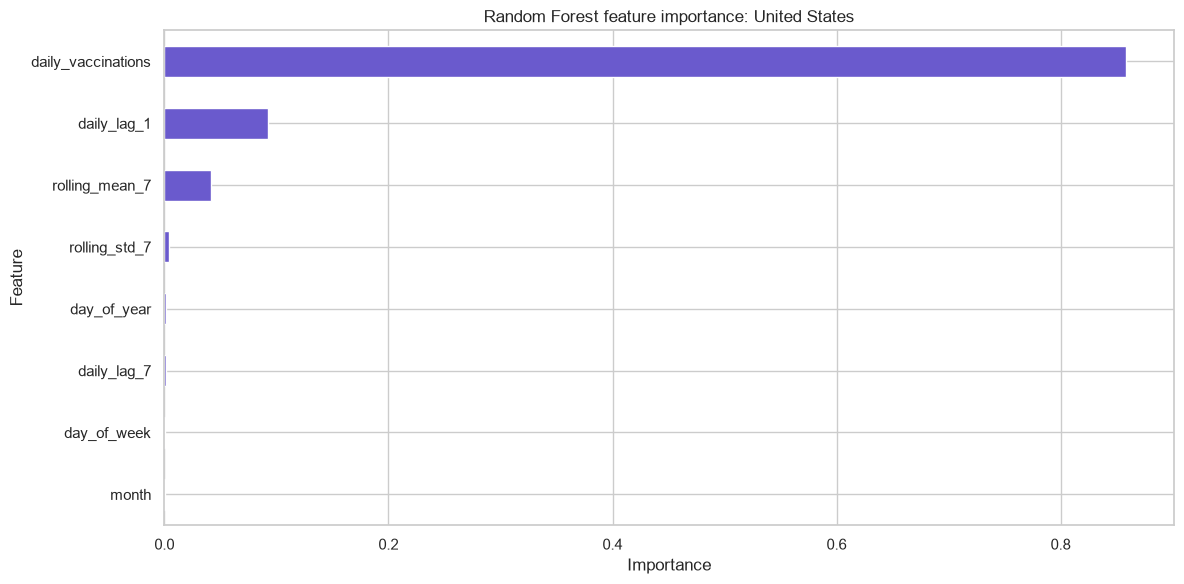

In [75]:
# Plot feature importance horizontal chart
feature_importance.sort_values().plot(kind="barh", color="slateblue")
plt.title(f"Random Forest feature importance: {COUNTRY}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [76]:
# Report training distribution baseline and model hyperparameters
print("Model:", model_pipeline.named_steps["regressor"])
print("Training target mean:", round(y_train.mean(), 2))
print("Training target median:", round(y_train.median(), 2))
print("Training target standard deviation:", round(y_train.std(), 2))

Model: RandomForestRegressor(min_samples_leaf=2, n_estimators=300, n_jobs=-1,
                      random_state=42)
Training target mean: 1804706.66
Training target median: 1809417.5
Training target standard deviation: 870079.98


## Test the model and show the metrics

In [77]:
# Predict next-day vaccination rates on unseen test set
test_predictions = model_pipeline.predict(X_test)

print("First five test predictions:", test_predictions[:5])
print("First five test targets:", y_test.iloc[:5].to_list())

First five test predictions: [1044208.49260847 1013330.59447222 1031626.94446958 1036526.73831482
 1070258.21109656]
First five test targets: [937669.0, 958533.0, 1026482.0, 1074204.0, 1120083.0]


In [78]:
# Compute and compare regression evaluation metrics against baseline
def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }

model_metrics = regression_metrics(y_test, test_predictions)
baseline_metrics = regression_metrics(y_test, baseline_predictions)

display(pd.DataFrame(
    [model_metrics, baseline_metrics],
    index=["Random Forest", "Persistence baseline"],
))

,MAE,RMSE,R2
Random Forest,116469.619433,146819.591172,0.635143
Persistence baseline,59230.682927,73374.595541,0.908873


In [79]:
# Compile test results and prediction residuals into evaluation dataframe
test_results = pd.DataFrame({
    "date": model_data.loc[X_test.index, "date"].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": test_predictions,
    "baseline": baseline_predictions,
})

test_results["residual"] = test_results["actual"] - test_results["predicted"]
display(test_results.head())

,date,actual,predicted,baseline,residual
0,2021-06-04,937669.0,1.044208e+06,1002963.0,-106539.492608
1,2021-06-05,958533.0,1.013331e+06,937669.0,-54797.594472
2,2021-06-06,1026482.0,1.031627e+06,958533.0,-5144.944470
3,2021-06-07,1074204.0,1.036527e+06,1026482.0,37677.261685
4,2021-06-08,1120083.0,1.070258e+06,1074204.0,49824.788903


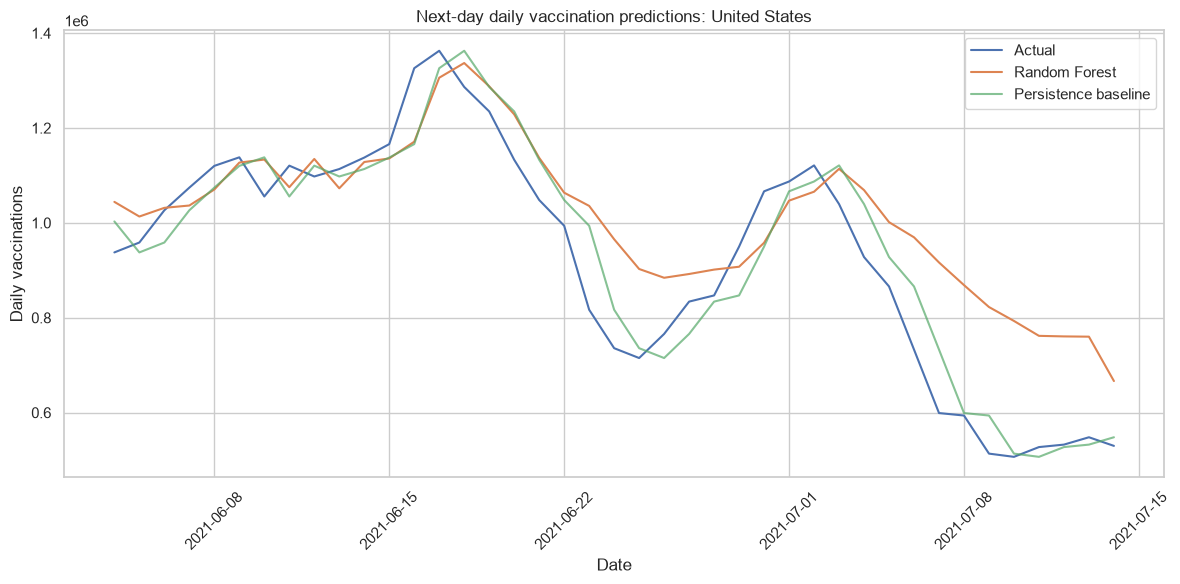

In [80]:
# Plot longitudinal forecast tracking versus actual observations
plt.plot(test_results["date"], test_results["actual"], label="Actual")
plt.plot(test_results["date"], test_results["predicted"], label="Random Forest")
plt.plot(test_results["date"], test_results["baseline"], label="Persistence baseline", alpha=0.7)
plt.title(f"Next-day daily vaccination predictions: {COUNTRY}")
plt.xlabel("Date")
plt.ylabel("Daily vaccinations")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

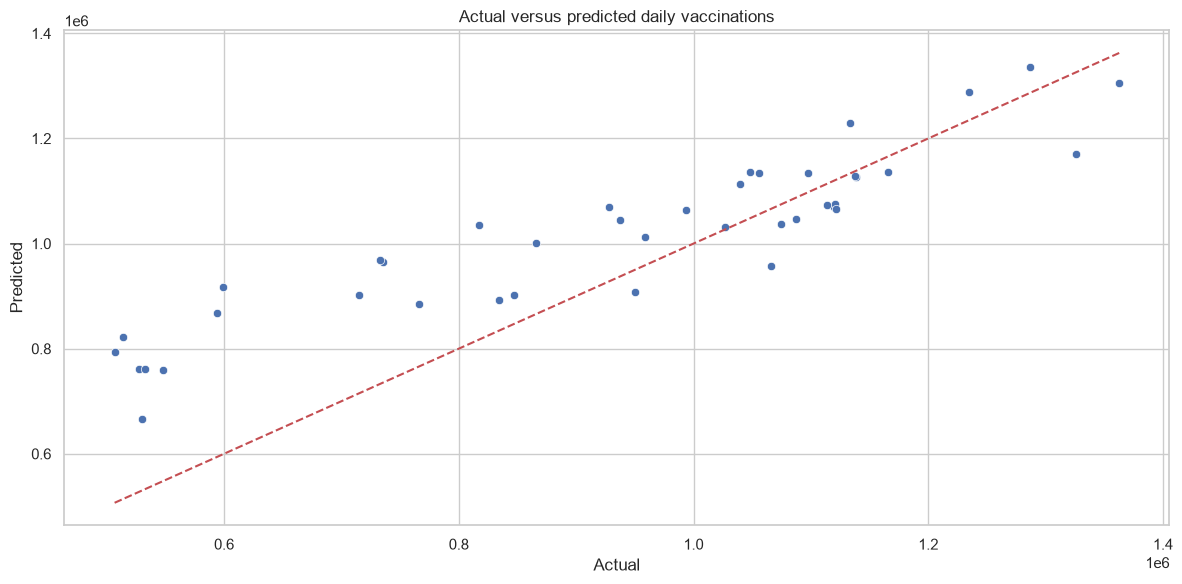

In [81]:
# Plot actual versus predicted scatterplot with identity line
sns.scatterplot(data=test_results, x="actual", y="predicted")
lower_bound = min(test_results["actual"].min(), test_results["predicted"].min())
upper_bound = max(test_results["actual"].max(), test_results["predicted"].max())
plt.plot([lower_bound, upper_bound], [lower_bound, upper_bound], "r--")
plt.title("Actual versus predicted daily vaccinations")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.tight_layout()
plt.show()

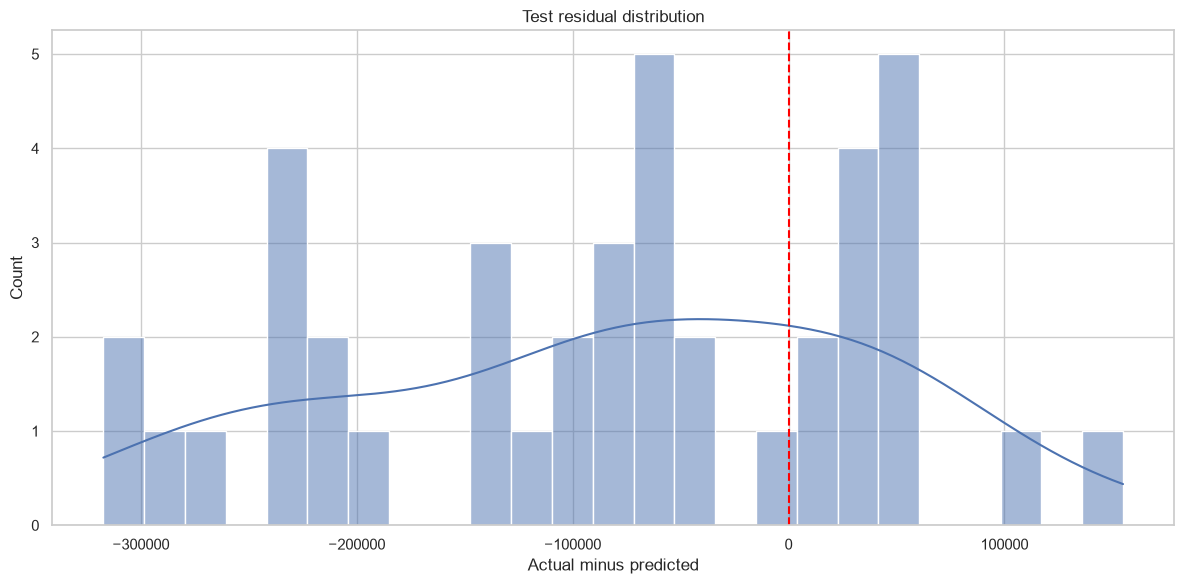

In [82]:
# Plot residual distribution and check error symmetry
sns.histplot(test_results["residual"], bins=25, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("Test residual distribution")
plt.xlabel("Actual minus predicted")
plt.tight_layout()
plt.show()

## Save your final model

In [83]:
# Package pipeline alongside required metadata for robust persistence
model_bundle = {
    "model": model_pipeline,
    "country": COUNTRY,
    "feature_columns": feature_columns,
    "target_column": target_column,
    "task": "predict next-calendar-day daily_vaccinations",
}

joblib.dump(model_bundle, "covid_vaccination_model.joblib")
print("Saved model bundle to covid_vaccination_model.joblib")

Saved model bundle to covid_vaccination_model.joblib


In [84]:
# Reload model bundle and verify prediction functionality
loaded_bundle = joblib.load("covid_vaccination_model.joblib")
loaded_model = loaded_bundle["model"]

verification_prediction = loaded_model.predict(X_test.iloc[:1])[0]
print("Reloaded model country:", loaded_bundle["country"])
print("Verification prediction:", verification_prediction)

Reloaded model country: United States
Verification prediction: 1044208.4926084657
